In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np

# Thiết lập phong cách đồ họa chuyên nghiệp cho Paper
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (16, 7)

# Khai báo file kết quả
result_files = {
    'ARIMA': 'data\\results\\arima_results.csv',
    'LSTM': 'data\\results\\lstm_close_results.csv',
    'Chronos': 'data\\results\\chronos_results.csv',
    'TimesFM': 'data\\results\\timesfm_results.csv',
    'Moirai': 'data\\results\\moirai_results.csv'
}

# Tải và gộp dữ liệu
dfs = []
for model_name, file_path in result_files.items():
    try:
        df = pd.read_csv(file_path)
        df['Model'] = model_name
        df['Date'] = pd.to_datetime(df['Date'])
        dfs.append(df)
    except FileNotFoundError:
        print(f"Warning: Không tìm thấy file {file_path}. Sẽ bỏ qua mô hình này.")

if dfs:
    all_results = pd.concat(dfs, ignore_index=True)
    print("Dữ liệu tải thành công!")
    print(f"Các mã Ticker có sẵn: {all_results['ticker'].unique()}")
else:
    print("Chưa có dữ liệu.")

Dữ liệu tải thành công!
Các mã Ticker có sẵn: ['ACB' 'BVH' 'CTG' 'FPT' 'GAS' 'HPG' 'KDH' 'MBB' 'MSN' 'PDR' 'SSI' 'STB'
 'VCB' 'VIC' 'VNM']


In [2]:
def plot_price_comparison(ticker_name, start_date=None, end_date=None):
    # Lọc dữ liệu theo mã cổ phiếu
    df_ticker = all_results[all_results['ticker'] == ticker_name].copy()
    
    # Cắt theo thời gian (nếu được yêu cầu)
    if start_date:
        df_ticker = df_ticker[df_ticker['Date'] >= pd.to_datetime(start_date)]
    if end_date:
        df_ticker = df_ticker[df_ticker['Date'] <= pd.to_datetime(end_date)]
        
    if df_ticker.empty:
        print(f"Không có dữ liệu cho mã {ticker_name}")
        return
        
    fig, ax = plt.subplots(figsize=(16, 7))
    
    # 1. Vẽ đường giá thực tế (Black, Solid Line)
    actual_data = df_ticker[df_ticker['Model'] == df_ticker['Model'].unique()[0]].sort_values('Date')
    ax.plot(actual_data['Date'], actual_data['target'], label='Actual Price', color='black', linewidth=2.5)
    
    # 2. Vẽ dự báo của từng model (Dashed Lines)
    colors = sns.color_palette("tab10", len(result_files))
    for i, model in enumerate(df_ticker['Model'].unique()):
        model_data = df_ticker[df_ticker['Model'] == model].sort_values('Date')
        
        # Lọc bỏ nhiễu: Loại bỏ các giá trị pred < 1.0 (tránh biểu đồ bị sụt về số 0)
        model_data.loc[model_data['pred'] < 1.0, 'pred'] = np.nan
        
        ax.plot(model_data['Date'], model_data['pred'], label=f'{model} Pred', 
                color=colors[i], linestyle='--', alpha=0.8, linewidth=1.5)

    # 3. Định dạng biểu đồ
    ax.set_title(f'Price Forecast Comparison: {ticker_name}', fontsize=16, fontweight='bold')
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Price Level (VND)', fontsize=12)
    
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    
    # Đưa chú thích ra bên ngoài để không che mất đường giá
    ax.legend(fontsize=11, loc='upper left', bbox_to_anchor=(1.01, 1))
    
    plt.tight_layout()
    plt.show()

print("Hàm vẽ đồ thị đã được nạp!")

Hàm vẽ đồ thị đã được nạp!


--- TOÀN BỘ GIAI ĐOẠN TEST ---


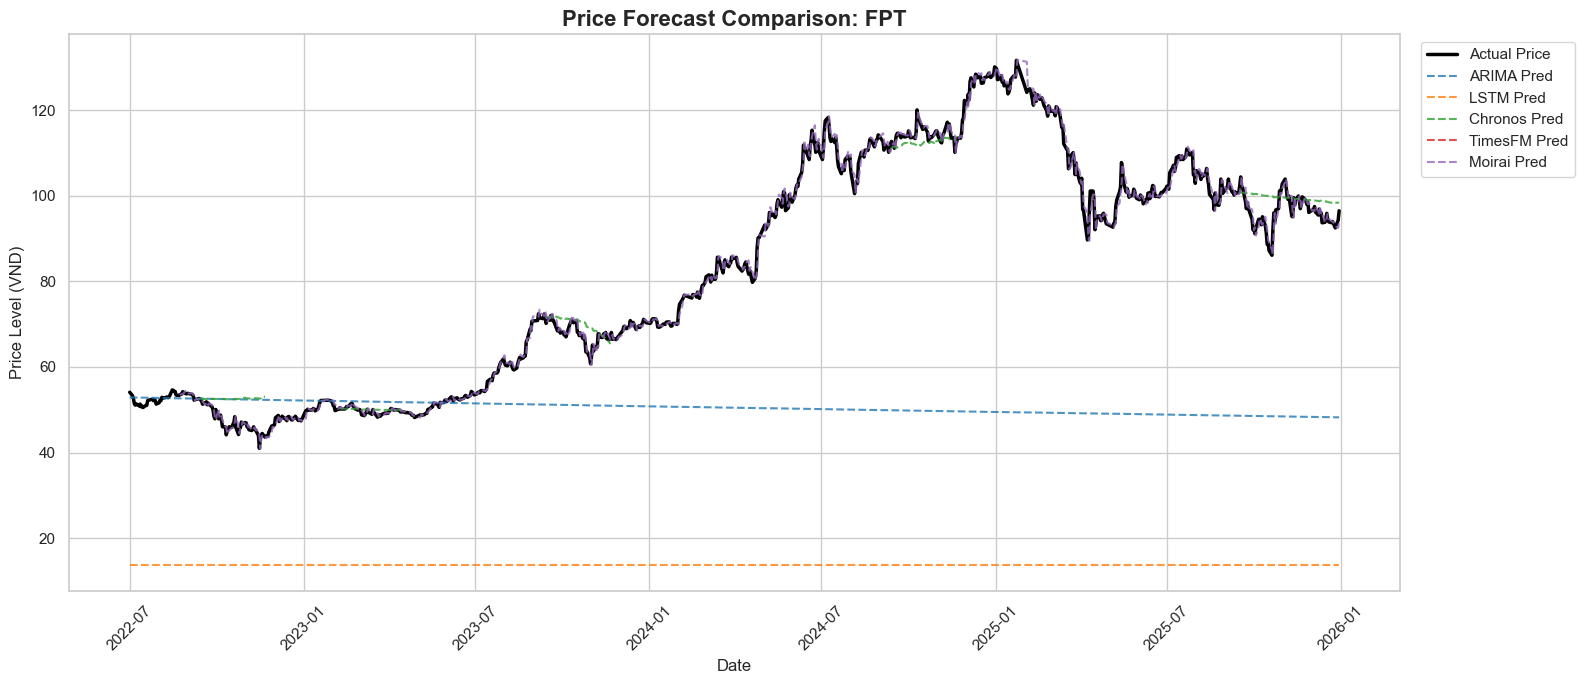


--- CẬN CẢNH GIAI ĐOẠN MARKET STRESS ---


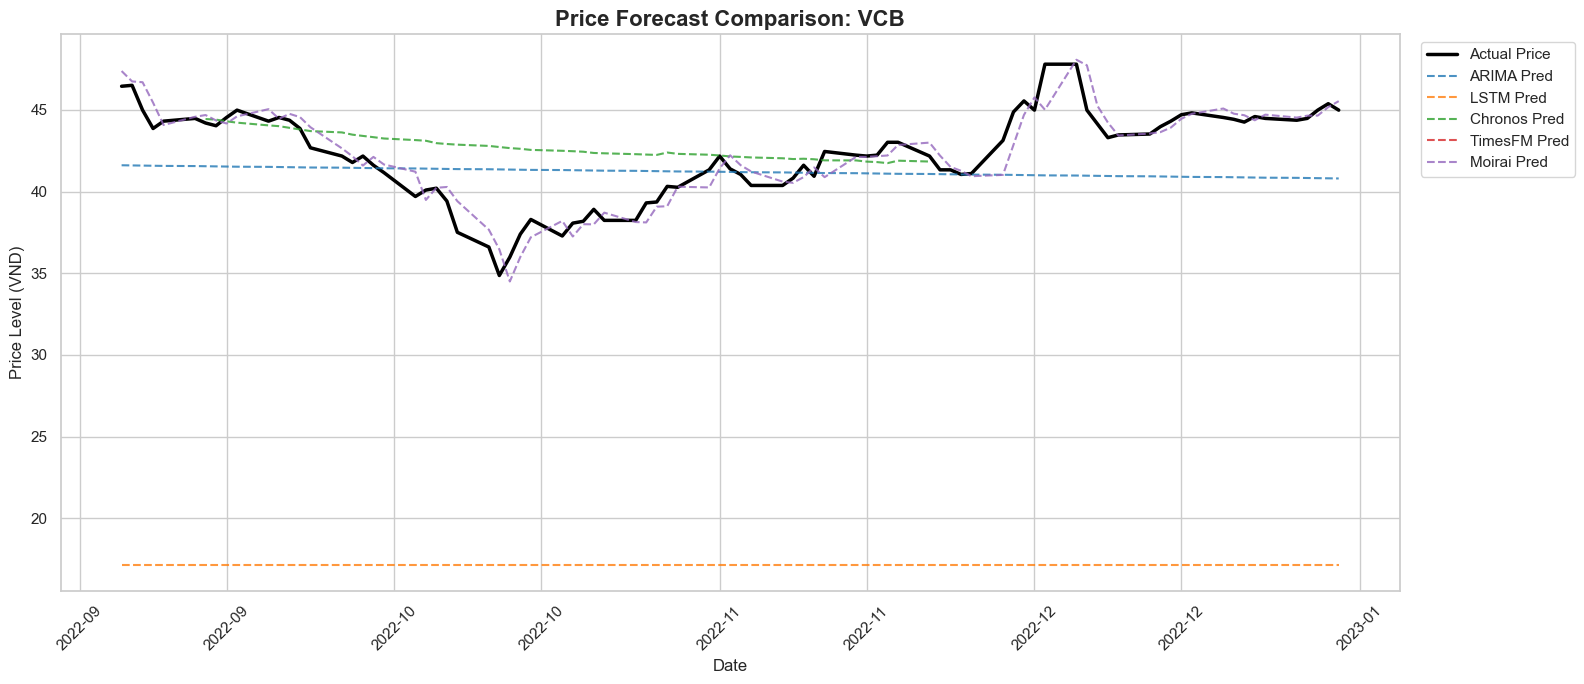

In [3]:
# Cách 1: Xem toàn bộ thời gian Test của một mã (VD: 'FPT')
print("--- TOÀN BỘ GIAI ĐOẠN TEST ---")
plot_price_comparison('FPT')

# Cách 2: Zoom cận cảnh vào một giai đoạn cụ thể (Case Study cho báo cáo)
# Ví dụ: Quan sát độ trễ (Lag Effect) của các model trong giai đoạn Bond Crisis (Tháng 9-12/2022)
print("\n--- CẬN CẢNH GIAI ĐOẠN MARKET STRESS ---")
plot_price_comparison('VCB', start_date='2022-09-01', end_date='2022-12-31')